In [ ]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import NASNetMobile, ConvNeXtTiny, InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt

2025-07-29 06:35:45.759600: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-29 06:35:45.989309: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1753770946.075777    2328 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1753770946.101318    2328 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1753770946.289313    2328 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [3]:
# Path to your single dataset folder (should have subfolders for each class)
data_dir = '/teamspace/studios/this_studio/Insect Dataset 7 class'  # e.g., 'vegetable_dataset/'

# Parameters
BATCH_SIZE = 32
IMG_SIZE = (224, 224)  # DenseNet121 default input size
NUM_CLASSES = 7
EPOCHS = 20
VAL_SPLIT = 0.2  # 20% for validation
TEST_SPLIT = 0.1  # 10% for testing

In [4]:
# Step 2: Load and preprocess dataset with progress bar
def load_dataset(data_dir):
    images = []
    labels = []

    for class_idx, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.exists(class_dir):
            print(f"Warning: Directory {class_dir} not found!")
            continue

        print(f"Loading {class_name} images...")
        for img_file in tqdm(os.listdir(class_dir)):
            img_path = os.path.join(class_dir, img_file)
            try:
                with Image.open(img_path) as img:
                    img = img.convert('RGB')  # Ensure RGB format
                    img = img.resize(IMAGE_SIZE)
                    img_array = np.array(img) / 255.0
                    if img_array.shape == (*IMAGE_SIZE, 3):
                        images.append(img_array)
                        labels.append(class_idx)
            except Exception as e:
                print(f"Error loading {img_path}: {e}")

    return np.array(images), np.array(labels)

In [5]:
pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import numpy as np
import tensorflow as tf
import random
from sklearn.model_selection import train_test_split
from collections import Counter
from tensorflow.keras.preprocessing.image import img_to_array, load_img, ImageDataGenerator

IMG_SIZE = (224, 224)
TARGET_PER_CLASS = 1000  # 3x from 500 original images

# 🏷️ Class names
class_names = sorted(os.listdir(data_dir))
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# 🎛️ Data Augmentation Setup
aug_gen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    shear_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# 🖼️ Load images and apply augmentation
all_images = []
all_labels = []

for class_idx, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    img_names = os.listdir(class_path)
    img_paths = [os.path.join(class_path, img) for img in img_names]

    # Load original images
    original_images = []
    for img_path in img_paths:
        img = load_img(img_path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        img_array = tf.keras.applications.mobilenet_v2.preprocess_input(img_array)
        original_images.append(img_array)

    # Add original images
    all_images.extend(original_images)
    all_labels.extend([class_idx] * len(original_images))

    # Number of augmented images to generate
    num_to_generate = TARGET_PER_CLASS - len(original_images)
    print(f"{class_name}: Generating {num_to_generate} augmented images")

    i = 0
    while i < num_to_generate:
        img = random.choice(original_images)
        img = np.expand_dims(img, axis=0)
        for batch in aug_gen.flow(img, batch_size=1):
            all_images.append(batch[0])
            all_labels.append(class_idx)
            i += 1
            if i >= num_to_generate:
                break

# 🔀 Final dataset
X = np.array(all_images)
y = np.array(all_labels)
print(f"\n✅ Total images after augmentation: {X.shape[0]}")
print("Class distribution:", Counter(y))

# 🔀 Split: 15% test, then 15% val, rest train
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

# 📦 TF Datasets
def create_dataset(X, y):
    return tf.data.Dataset.from_tensor_slices((X, tf.one_hot(y, depth=NUM_CLASSES)))

train_ds = create_dataset(X_train, y_train).shuffle(1000).batch(BATCH_SIZE)
val_ds = create_dataset(X_val, y_val).batch(BATCH_SIZE)
test_ds = create_dataset(X_test, y_test).batch(BATCH_SIZE)

# 🧾 Summary
print("\n✅ Final dataset shapes:")
print("Train:", X_train.shape, " | ", Counter(y_train))
print("Val  :", X_val.shape, " | ", Counter(y_val))
print("Test :", X_test.shape, " | ", Counter(y_test))


Classes: ['Green lacewigs', 'Hadda beetle', 'Hoverfly', 'Lady beetle', 'Mirid Bug', 'Noctuidae', 'Plant bugs']


Green lacewigs: Generating 700 augmented images
Hadda beetle: Generating 888 augmented images
Hoverfly: Generating 892 augmented images
Lady beetle: Generating 840 augmented images
Mirid Bug: Generating 840 augmented images
Noctuidae: Generating 858 augmented images
Plant bugs: Generating 822 augmented images

✅ Total images after augmentation: 7000
Class distribution: Counter({0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000})


I0000 00:00:1753771031.169468    2328 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79091 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:00:05.0, compute capability: 8.0



✅ Final dataset shapes:
Train: (4899, 224, 224, 3)  |  Counter({0: 700, 4: 700, 1: 700, 5: 700, 3: 700, 2: 700, 6: 699})
Val  : (1051, 224, 224, 3)  |  Counter({6: 151, 4: 150, 5: 150, 3: 150, 0: 150, 1: 150, 2: 150})
Test : (1050, 224, 224, 3)  |  Counter({3: 150, 2: 150, 6: 150, 4: 150, 1: 150, 0: 150, 5: 150})


In [7]:
from tensorflow.keras.applications import NASNetMobile, ConvNeXtTiny, InceptionV3
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, Average, Lambda
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

# Constants
INPUT_SHAPE = (224, 224, 3)
NUM_CLASSES = 7  # Adjust according to your dataset

def create_individual_model(base_model_class, dropout_rate=0.2):
    """Helper function to create individual models with consistent architecture"""
    base_model = base_model_class(weights="imagenet", include_top=False, input_shape=INPUT_SHAPE)
    base_model.trainable = True
    
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    predictions = Dense(NUM_CLASSES, activation='softmax')(x)
    
    return Model(inputs=base_model.input, outputs=predictions)

def build_ensemble():
    """Build the ensemble model combining all three models"""
    # Create individual models
    nasnet = create_individual_model(NASNetMobile, dropout_rate=0.2)
    convnext = create_individual_model(ConvNeXtTiny, dropout_rate=0.2)
    inception = create_individual_model(InceptionV3, dropout_rate=0.5)
    
    # Give them identifiable names
    nasnet._name = 'nasnet'
    convnext._name = 'convnext'
    inception._name = 'inception'
    
    # Create separate input layers for each model
    input_nasnet = Input(shape=INPUT_SHAPE, name='input_nasnet')
    input_convnext = Input(shape=INPUT_SHAPE, name='input_convnext')
    input_inception = Input(shape=INPUT_SHAPE, name='input_inception')
    
    # Get individual predictions
    pred_nasnet = nasnet(input_nasnet)
    pred_convnext = convnext(input_convnext)
    pred_inception = inception(input_inception)
    
    # Weighted average based on your validation accuracies
    weights = {
        'nasnet': 0.35,    # NASNetMobile 99.05%
        'convnext': 0.33,  # ConvNeXtTiny 98.76%
        'inception': 0.32  # InceptionV3 98.67%
    }
    
    # Weighted predictions using Keras Lambda layer
    weighted_nasnet = Lambda(lambda x: x * weights['nasnet'])(pred_nasnet)
    weighted_convnext = Lambda(lambda x: x * weights['convnext'])(pred_convnext)
    weighted_inception = Lambda(lambda x: x * weights['inception'])(pred_inception)
    
    weighted_avg = Average()([weighted_nasnet, weighted_convnext, weighted_inception])
    
    # Create ensemble model
    ensemble_model = Model(
        inputs=[input_nasnet, input_convnext, input_inception],
        outputs=weighted_avg,
        name='top3_ensemble'
    )
    
    return ensemble_model, [nasnet, convnext, inception]

def compile_ensemble(ensemble_model):
    """Compile the ensemble model"""
    ensemble_model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )

# Create and compile the ensemble
ensemble_model, individual_models = build_ensemble()
compile_ensemble(ensemble_model)

# Print model summary
ensemble_model.summary()


Model: "top3_ensemble"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_nasnet        │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_convnext      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_inception     │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 7)         │  4,814,491 │ input_nasnet[0][… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_5        │ (None, 7)         │ 28,217,447 │ input_convnext[0… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_6        │ (None, 7)         │ 22,855,463 │ input_inception[… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 7)         │          0 │ functional[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 7)         │          0 │ functional_5[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 7)         │          0 │ functional_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average (Average)   │ (None, 7)         │          0 │ lambda[0][0],     │
│                     │                   │            │ lambda_1[0][0],   │
│                     │                   │            │ lambda_2[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 55,887,401 (213.19 MB)

 Trainable params: 55,816,231 (212.92 MB)

 Non-trainable params: 71,170 (278.01 KB)

In [8]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Adapt dataset to provide 3 identical inputs for the ensemble
def adapt_for_ensemble(ds):
    return ds.map(lambda x, y: ((x, x, x), y))

# Adapt train and val datasets
train_ds_ensemble = adapt_for_ensemble(train_ds)
val_ds_ensemble = adapt_for_ensemble(val_ds)

# Define model name
model_name = "top3_ensemble"

# Callbacks
checkpoint = ModelCheckpoint(
    f"{model_name}.h5",
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-4,
    verbose=1
)

# Compile the ensemble model (if not already compiled)
ensemble_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# Train the ensemble model
history = ensemble_model.fit(
    train_ds_ensemble,
    validation_data=val_ds_ensemble,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stop, reduce_lr]
)


Epoch 1/20


I0000 00:00:1753771197.787595    3629 service.cc:152] XLA service 0x71ff100954b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753771197.787683    3629 service.cc:160]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2025-07-29 06:40:04.456803: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1753771230.458191    3629 cuda_dnn.cc:529] Loaded cuDNN version 90701
2025-07-29 06:40:50.633245: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_69390_0', 96 bytes spill stores, 96 bytes spill loads

2025-07-29 06:40:50.893383: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6939

153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.8514 - loss: 0.5705 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00

2025-07-29 06:44:55.582959: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_69390', 300 bytes spill stores, 300 bytes spill loads

2025-07-29 06:44:55.873855: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_69390', 76 bytes spill stores, 76 bytes spill loads

2025-07-29 06:44:56.657123: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1', 256 bytes spill stores, 256 bytes spill loads

2025-07-29 06:44:56.761744: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 120 bytes spill stores, 120 bytes spill loads

2025-07-29 06:44:56.824239: I external/l

154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8519 - loss: 0.5685 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00   

...

154/154 ━━━━━━━━━━━━━━━━━━━━ 46s 297ms/step - accuracy: 0.9977 - loss: 0.0137 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9943 - val_loss: 0.0796 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.9978 - loss: 0.0115 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 4: val_accuracy improved from 0.99429 to 0.99524, saving model to top3_ensemble.h5


154/154 ━━━━━━━━━━━━━━━━━━━━ 44s 286ms/step - accuracy: 0.9978 - loss: 0.0115 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9952 - val_loss: 0.0539 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.9996 - loss: 0.0073 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 5: val_accuracy improved from 0.99524 to 0.99619, saving model to top3_ensemble.h5


154/154 ━━━━━━━━━━━━━━━━━━━━ 43s 278ms/step - accuracy: 0.9996 - loss: 0.0073 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9962 - val_loss: 0.0884 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.9995 - loss: 0.0061 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 6: val_accuracy did not improve from 0.99619
154/154 ━━━━━━━━━━━━━━━━━━━━ 38s 248ms/step - accuracy: 0.9995 - loss: 0.0061 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9962 - val_loss: 0.0680 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 7/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 1.0000 - loss: 0.0040 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 7: val_accuracy did not improve from 0.99619
154/154 ━━━━━━━━━━━━━━━━━━━━ 39s 254ms/step - accuracy: 1.0000 - loss: 0.0040 - precision_1: 0.0000e+00 - recall_1: 

154/154 ━━━━━━━━━━━━━━━━━━━━ 43s 282ms/step - accuracy: 1.0000 - loss: 0.0026 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9971 - val_loss: 0.0338 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 9/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 1.0000 - loss: 0.0023 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 9: val_accuracy did not improve from 0.99715
154/154 ━━━━━━━━━━━━━━━━━━━━ 38s 249ms/step - accuracy: 1.0000 - loss: 0.0023 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9933 - val_loss: 0.0389 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 10/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 1.0000 - loss: 0.0051 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 10: val_accuracy did not improve from 0.99715
154/154 ━━━━━━━━━━━━━━━━━━━━ 41s 263ms/step - accuracy: 1.0000 - loss: 0.0051 - precision_1: 0.0000e+00 - recall_1

154/154 ━━━━━━━━━━━━━━━━━━━━ 46s 299ms/step - accuracy: 0.9987 - loss: 0.0060 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9981 - val_loss: 0.0219 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 18/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.9998 - loss: 0.0044 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 18: val_accuracy did not improve from 0.99810
154/154 ━━━━━━━━━━━━━━━━━━━━ 38s 249ms/step - accuracy: 0.9998 - loss: 0.0044 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00 - val_accuracy: 0.9943 - val_loss: 0.0526 - val_precision_1: 0.0000e+00 - val_recall_1: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 19/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 1.0000 - loss: 0.0041 - precision_1: 0.0000e+00 - recall_1: 0.0000e+00
Epoch 19: val_accuracy did not improve from 0.99810
154/154 ━━━━━━━━━━━━━━━━━━━━ 39s 252ms/step - accuracy: 1.0000 - loss: 0.0041 - precision_1: 0.0000e+00 - recall

In [9]:
pip install seaborn


Note: you may need to restart the kernel to use updated packages.


32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step

2025-07-29 07:02:09.844985: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6460_0', 96 bytes spill stores, 96 bytes spill loads

2025-07-29 07:02:10.004868: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6460', 76 bytes spill stores, 76 bytes spill loads

2025-07-29 07:02:10.057889: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6467', 324 bytes spill stores, 324 bytes spill loads

2025-07-29 07:02:10.305708: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6460', 536 bytes spill stores, 536 bytes spill loads

2025-07-29 07:02:10.372983: I exte

33/33 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step
Classification Report:



2025-07-29 07:02:45.825848: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


                precision    recall  f1-score   support

Green lacewigs       0.97      1.00      0.99       150
  Hadda beetle       0.99      1.00      1.00       150
      Hoverfly       0.99      1.00      1.00       150
   Lady beetle       0.99      0.99      0.99       150
     Mirid Bug       0.99      0.96      0.98       150
     Noctuidae       1.00      1.00      1.00       150
    Plant bugs       0.98      0.98      0.98       150

      accuracy                           0.99      1050
     macro avg       0.99      0.99      0.99      1050
  weighted avg       0.99      0.99      0.99      1050


Confusion matrix, without normalization


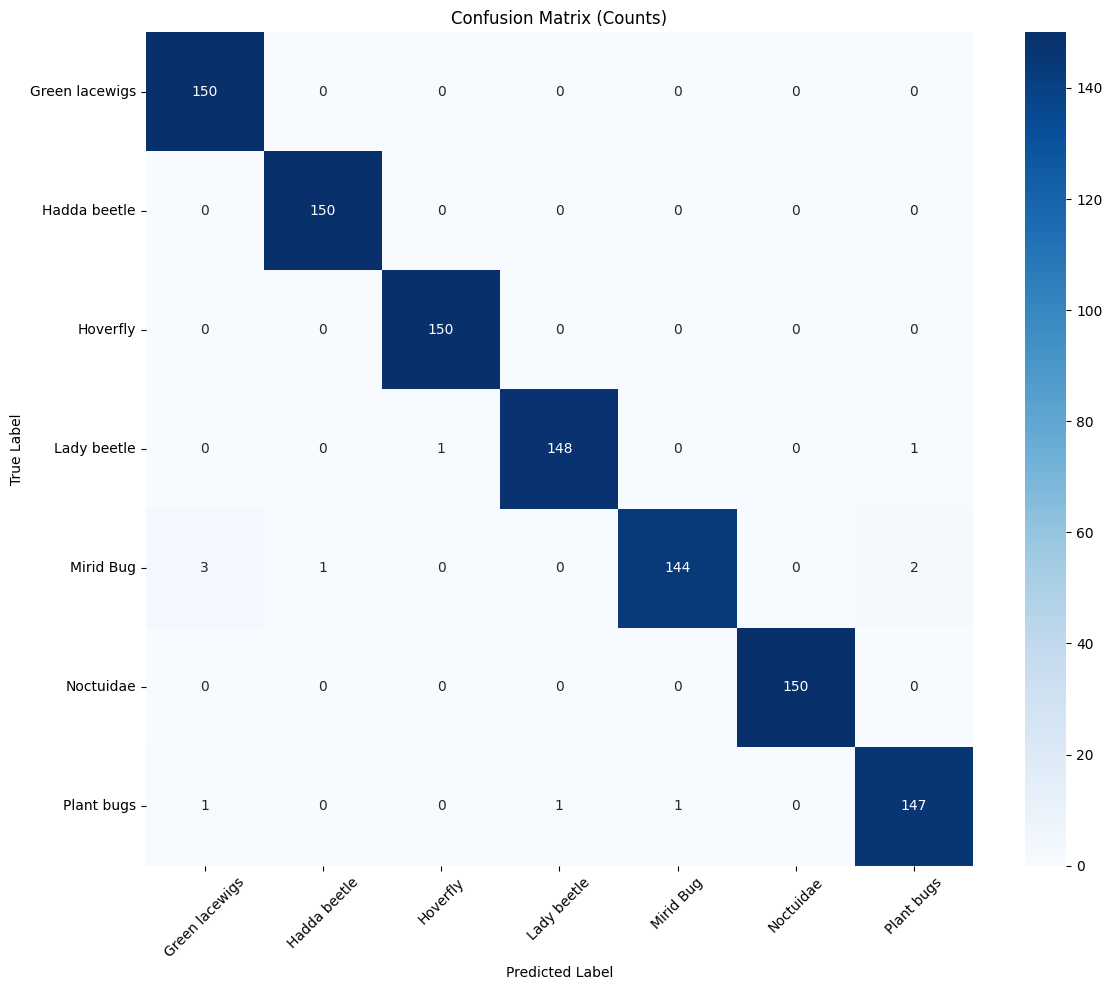


Normalized confusion matrix


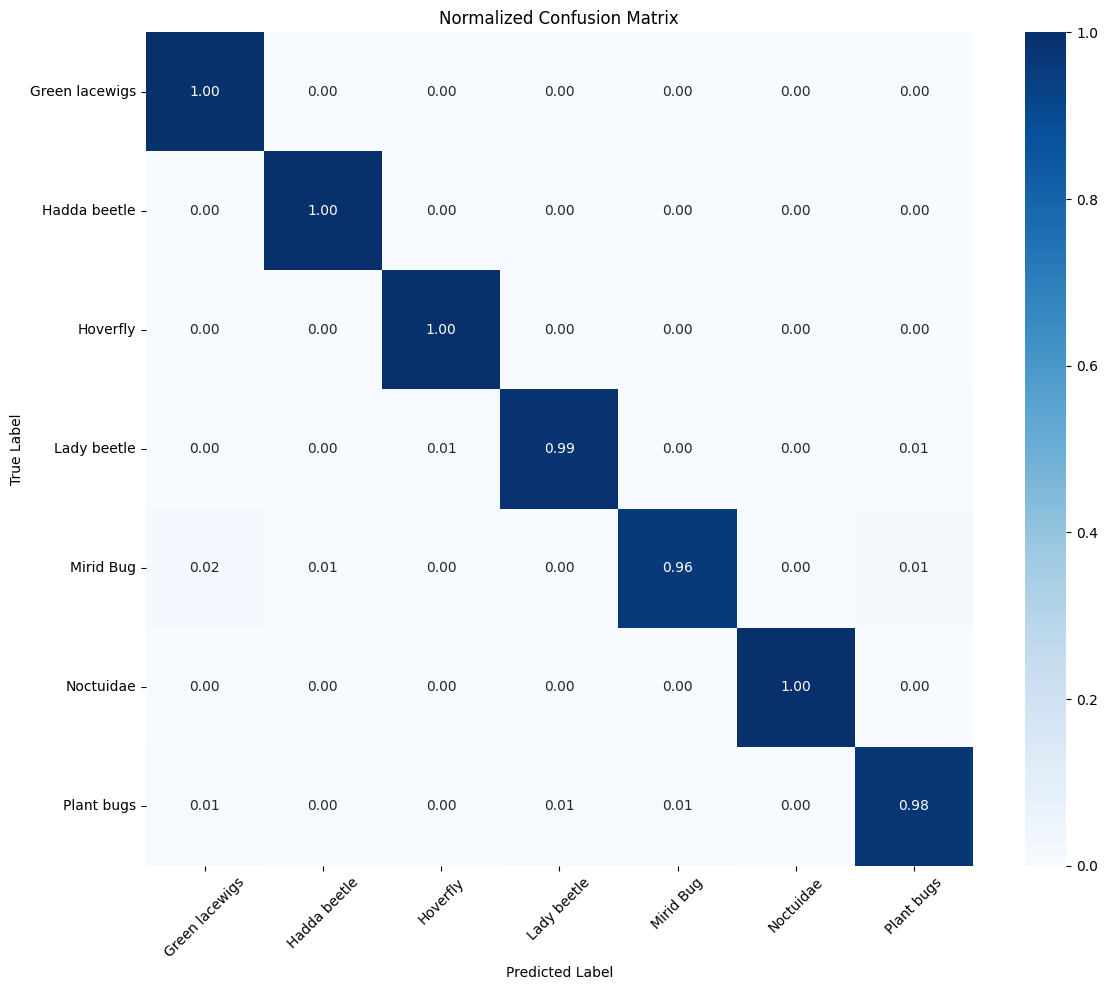

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# ✅ Ensemble expects 3 inputs, so we must pass (x, x, x)
def prepare_test_for_prediction(ds):
    return ds.map(lambda x, y: ((x, x, x), y))

# 🧪 Prepare test dataset for prediction
test_ds_ens = prepare_test_for_prediction(test_ds)

# 🔍 Predict
y_pred_probs = ensemble_model.predict(test_ds_ens)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# 🎯 Extract true labels
y_true = []
for _, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

# 🧾 Classification report
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# 📊 Confusion matrix plotting function
def plot_confusion_matrix(y_true, y_pred, classes, normalize=False, title='Confusion Matrix', cmap=plt.cm.Blues):
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
        print("\nNormalized confusion matrix")
    else:
        print("\nConfusion matrix, without normalization")

    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd',
                cmap=cmap, xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 🖼️ Plot both confusion matrices
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names, title='Confusion Matrix (Counts)')
plot_confusion_matrix(y_true, y_pred_classes, classes=class_names, normalize=True, title='Normalized Confusion Matrix')


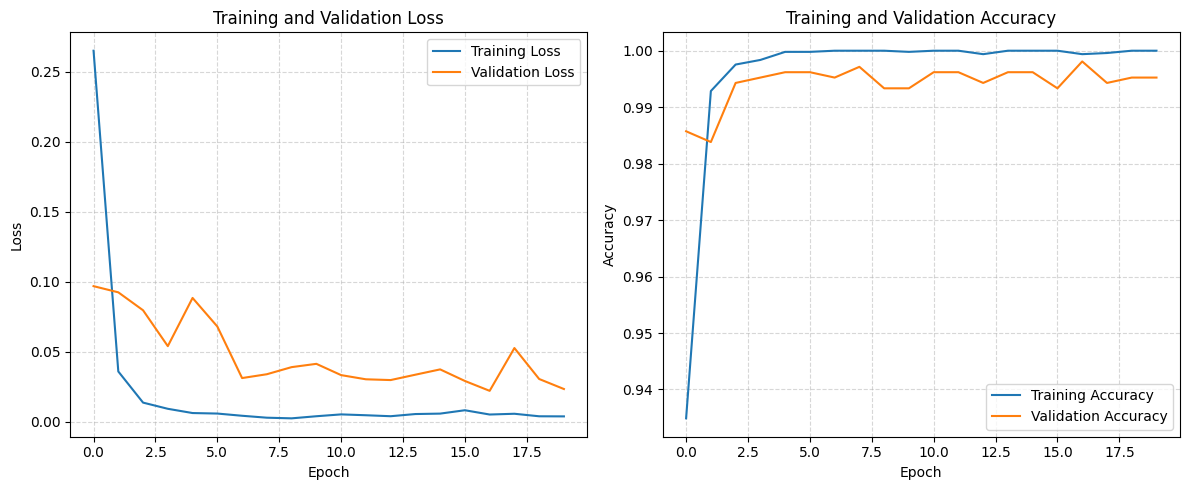


📉 Best Validation Loss: 0.0219 at epoch 17
   Training Loss at that epoch: 0.0050
   Validation Accuracy at that epoch: 0.9981


In [11]:
import matplotlib.pyplot as plt
import numpy as np  # Ensure numpy is imported

# ✅ Make sure to pass the correct 'history' object from model.fit()
# Example: history = train_ensemble(ensemble_model, train_ds, val_ds, epochs=...)
history_dict = history.history

# 📊 Create figure with two subplots
plt.figure(figsize=(12, 5))

# 1️⃣ Plot Loss Curves
plt.subplot(1, 2, 1)
plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 2️⃣ Plot Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(history_dict['accuracy'], label='Training Accuracy')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 🏆 Optional: Print best validation loss & related info
best_val_epoch = np.argmin(history_dict['val_loss'])
print(f"\n📉 Best Validation Loss: {history_dict['val_loss'][best_val_epoch]:.4f} at epoch {best_val_epoch + 1}")
print(f"   Training Loss at that epoch: {history_dict['loss'][best_val_epoch]:.4f}")
print(f"   Validation Accuracy at that epoch: {history_dict['val_accuracy'][best_val_epoch]:.4f}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step


2025-07-29 07:02:49.342118: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


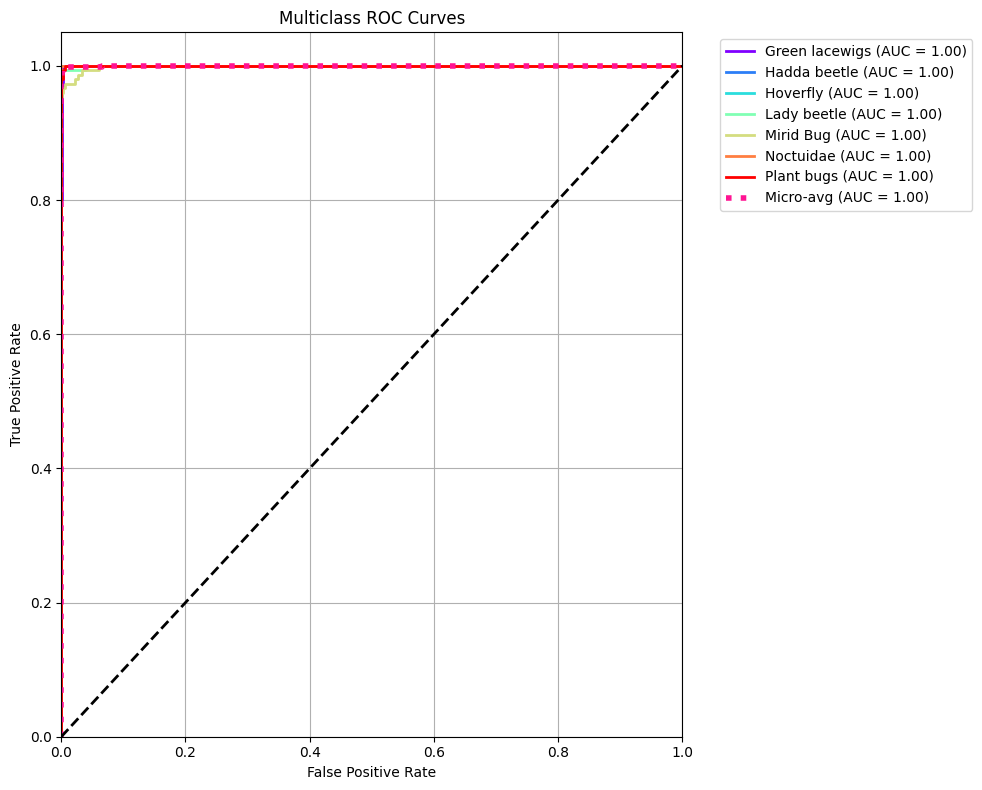


📊 AUC Scores:
Green lacewigs: 0.9997
Hadda beetle: 1.0000
Hoverfly: 1.0000
Lady beetle: 0.9997
Mirid Bug: 0.9990
Noctuidae: 1.0000
Plant bugs: 0.9999

Micro-average AUC: 0.9999


In [12]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

# ✅ Step 1: Prepare test dataset for ensemble model (x, x, x)
def prepare_test_for_prediction(ds):
    return ds.map(lambda x, y: ((x, x, x), y))

test_ds_ens = prepare_test_for_prediction(test_ds)

# ✅ Step 2: Get predictions from model
y_pred = ensemble_model.predict(test_ds_ens)

# ✅ Step 3: Get true labels from one-hot encoded test set
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true_labels = np.argmax(y_true, axis=1)  # Convert one-hot to labels

# ✅ Step 4: Binarize the true labels for ROC
y_true_bin = label_binarize(y_true_labels, classes=np.arange(NUM_CLASSES))

# ✅ Step 5: Compute ROC curves and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ✅ Step 6: Compute micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# ✅ Step 7: Plot ROC curves
plt.figure(figsize=(10, 8))
colors = cycle(plt.cm.rainbow(np.linspace(0, 1, NUM_CLASSES)))

for i, color in zip(range(NUM_CLASSES), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:0.2f})')

# Micro-average curve
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-avg (AUC = {roc_auc["micro"]:0.2f})',
         color='deeppink', linestyle=':', linewidth=4)

# Random baseline
plt.plot([0, 1], [0, 1], 'k--', lw=2)

# Final plot settings
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# ✅ Step 8: Print AUC scores
print("\n📊 AUC Scores:")
for i in range(NUM_CLASSES):
    print(f"{class_names[i]}: {roc_auc[i]:.4f}")
print(f"\nMicro-average AUC: {roc_auc['micro']:.4f}")
